# 🔍 01 — Data Exploration & Understanding (UPDATED)
### Scouti Kora — AI Football Scouting System
**Datasets covered:**
- FBref scraped: `ALL_STATS.csv`, `ALL_WAGES.csv`
- Transfermarkt Kaggle: `players`, `player_valuations`, `transfers`, `appearances`, `clubs`, `competitions`, `games`
- Transfermarkt scraped: `TM_PLAYER_VALUES.csv`, `TM_INJURIES.csv`, `TM_RUMORS.csv`, `TM_RECENT_TRANSFERS.csv`

**Goal:** Understand every column, types, nulls, cleaning needs, pipeline strategy.

---

## 📦 0 — Imports & Config

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import warnings, os, json, re, unicodedata
from pathlib import Path

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)
pd.set_option('display.float_format', '{:.2f}'.format)

plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.grid': True, 'grid.alpha': 0.3,
    'axes.spines.top': False, 'axes.spines.right': False,
    'font.size': 11,
})
COLORS = ['#7F77DD','#1D9E75','#D85A30','#378ADD','#BA7517','#D4537E']

ROOT      = Path('..').resolve()
RAW       = ROOT / 'data' / 'raw'
SCRAPED   = ROOT / 'data' / 'scraped'
PROCESSED = ROOT / 'data' / 'processed'
REPORTS   = ROOT / 'reports'
PROCESSED.mkdir(exist_ok=True)
REPORTS.mkdir(exist_ok=True)

# Identity columns common across all stat types — not stats themselves
IDENTITY = {
    'Rk','Player','Nation','Pos','Squad','Age','Born','Matches',
    'level','league','season','stat_type','Playing Time_MP',
    'Playing Time_Starts','Playing Time_Min','Playing Time_90s','90s'
}

print('✅ Config ready')
print(f'   RAW:      {RAW}')
print(f'   SCRAPED:  {SCRAPED}')
print(f'   PROCESSED:{PROCESSED}')

✅ Config ready
   RAW:      C:\Users\Lenovo\Scouti_Koora\data\raw
   SCRAPED:  C:\Users\Lenovo\Scouti_Koora\data\scraped
   PROCESSED:C:\Users\Lenovo\Scouti_Koora\data\processed


## 📂 1 — Load All Datasets

In [13]:
def safe_read(path, label=None):
    p = Path(path)
    name = label or p.name
    if p.exists():
        df = pd.read_csv(p, low_memory=False)
        print(f'  ✅ {name:<35} {len(df):>9,} rows × {len(df.columns)} cols')
        return df
    print(f'  ⚠️  {name:<35} NOT FOUND')
    return pd.DataFrame()

print('── FBref scraped ─────────────────────────────────────')
all_stats = safe_read(SCRAPED / 'ALL_STATS.csv')
all_wages = safe_read(SCRAPED / 'ALL_WAGES.csv')

print('\n── Transfermarkt Kaggle ──────────────────────────────')
players     = safe_read(RAW / 'players.csv')
valuations  = safe_read(RAW / 'player_valuations.csv')
transfers   = safe_read(RAW / 'transfers.csv')
appearances = safe_read(RAW / 'appearances.csv')
clubs       = safe_read(RAW / 'clubs.csv')
competitions= safe_read(RAW / 'competitions.csv')
games       = safe_read(RAW / 'games.csv')

print('\n── Transfermarkt scraped ─────────────────────────────')
tm_values    = safe_read(SCRAPED / 'TM_PLAYER_VALUES.csv')
tm_injuries  = safe_read(SCRAPED / 'TM_INJURIES.csv')
tm_rumors    = safe_read(SCRAPED / 'TM_RUMORS.csv')
tm_transfers = safe_read(SCRAPED / 'TM_RECENT_TRANSFERS.csv')

# Build dataset registry
datasets = {
    'all_stats': all_stats,   'all_wages': all_wages,
    'players': players,       'valuations': valuations,
    'transfers': transfers,   'appearances': appearances,
    'clubs': clubs,           'competitions': competitions,
    'games': games,
}
for k, v in [('tm_values', tm_values),('tm_injuries', tm_injuries),
              ('tm_rumors', tm_rumors),('tm_transfers', tm_transfers)]:
    if not v.empty: datasets[k] = v

total_rows = sum(len(v) for v in datasets.values())
print(f'\n  TOTAL rows across all datasets: {total_rows:,}')

── FBref scraped ─────────────────────────────────────
  ✅ ALL_STATS.csv                         100,186 rows × 124 cols
  ✅ ALL_WAGES.csv                          15,017 rows × 16 cols

── Transfermarkt Kaggle ──────────────────────────────
  ✅ players.csv                            47,702 rows × 26 cols
  ✅ player_valuations.csv                 616,377 rows × 6 cols
  ✅ transfers.csv                         157,186 rows × 10 cols
  ✅ appearances.csv                     1,862,208 rows × 13 cols
  ✅ clubs.csv                                 796 rows × 17 cols
  ✅ competitions.csv                           67 rows × 11 cols
  ✅ games.csv                              86,983 rows × 23 cols

── Transfermarkt scraped ─────────────────────────────
  ✅ TM_PLAYER_VALUES.csv                   18,937 rows × 11 cols
  ✅ TM_INJURIES.csv                         2,246 rows × 9 cols
  ⚠️  TM_RUMORS.csv                       NOT FOUND
  ✅ TM_RECENT_TRANSFERS.csv                   223 rows × 8 cols

  

In [14]:
# ── Compatibility layer: map new prefixed cols → old names ──────────
# The new scraper prefixes columns per stat_type to avoid collisions.
# This mapping lets the rest of the notebook use the old names unchanged.

PREFIX_MAP = {
    # standard
    'std_Performance_Gls':          'Performance_Gls',
    'std_Performance_Ast':          'Performance_Ast',
    'std_Performance_G+A':          'Performance_G+A',
    'std_Performance_G-PK':         'Performance_G-PK',
    'std_Performance_PK':           'Performance_PK',
    'std_Performance_PKatt':        'Performance_PKatt',
    'std_Performance_CrdY':         'Performance_CrdY',
    'std_Performance_CrdR':         'Performance_CrdR',
    'std_Per 90 Minutes_Gls':       'Per 90 Minutes_Gls',
    'std_Per 90 Minutes_Ast':       'Per 90 Minutes_Ast',
    'std_Per 90 Minutes_G+A':       'Per 90 Minutes_G+A',
    'std_Per 90 Minutes_G-PK':      'Per 90 Minutes_G-PK',
    'std_Per 90 Minutes_G+A-PK':    'Per 90 Minutes_G+A-PK',
    'std_Playing Time_MP':          'Playing Time_MP',
    'std_Playing Time_Starts':      'Playing Time_Starts',
    'std_Playing Time_Min':         'Playing Time_Min',
    'std_Playing Time_90s':         'Playing Time_90s',
    # shooting
    'sh_Standard_Gls':              'Standard_Gls',
    'sh_Standard_Sh':               'Standard_Sh',
    'sh_Standard_SoT':              'Standard_SoT',
    'sh_Standard_SoT%':             'Standard_SoT%',
    'sh_Standard_Sh/90':            'Standard_Sh/90',
    'sh_Standard_SoT/90':           'Standard_SoT/90',
    'sh_Standard_G/Sh':             'Standard_G/Sh',
    'sh_Standard_G/SoT':            'Standard_G/SoT',
    'sh_Standard_PK':               'Standard_PK',
    'sh_Standard_PKatt':            'Standard_PKatt',
    # passing
    'pass_Total_Cmp':               'Total_Cmp',
    'pass_Total_Att':               'Total_Att',
    'pass_Total_Cmp%':              'Total_Cmp%',
    'pass_Total_TotDist':           'Total_TotDist',
    'pass_Total_PrgDist':           'Total_PrgDist',
    'pass_Short_Cmp':               'Short_Cmp',
    'pass_Short_Att':               'Short_Att',
    'pass_Short_Cmp%':              'Short_Cmp%',
    'pass_Medium_Cmp':              'Medium_Cmp',
    'pass_Medium_Att':              'Medium_Att',
    'pass_Medium_Cmp%':             'Medium_Cmp%',
    'pass_Long_Cmp':                'Long_Cmp',
    'pass_Long_Att':                'Long_Att',
    'pass_Long_Cmp%':               'Long_Cmp%',
    'pass_Ast':                     'Ast',
    'pass_A-xAG':                   'A-xAG',
    'pass_KP':                      'KP',
    'pass_1/3':                     '1/3',
    'pass_PPA':                     'PPA',
    'pass_CrsPA':                   'CrsPA',
    # defense
    'def_Tackles_Tkl':              'Tackles_Tkl',
    'def_Tackles_TklW':             'Tackles_TklW',
    'def_Tackles_Def 3rd':          'Tackles_Def 3rd',
    'def_Tackles_Mid 3rd':          'Tackles_Mid 3rd',
    'def_Tackles_Att 3rd':          'Tackles_Att 3rd',
    'def_Challenges_Tkl':           'Challenges_Tkl',
    'def_Challenges_Att':           'Challenges_Att',
    'def_Challenges_Tkl%':          'Challenges_Tkl%',
    'def_Challenges_Lost':          'Challenges_Lost',
    'def_Blocks_Blocks':            'Blocks_Blocks',
    'def_Blocks_Sh':                'Blocks_Sh',
    'def_Blocks_Pass':              'Blocks_Pass',
    'def_Int':                      'Int',
    'def_Tkl+Int':                  'Tkl+Int',
    'def_Clr':                      'Clr',
    'def_Err':                      'Err',
    # possession
    'poss_Touches_Touches':         'Touches_Touches',
    'poss_Touches_Def Pen':         'Touches_Def Pen',
    'poss_Touches_Def 3rd':         'Touches_Def 3rd',
    'poss_Touches_Mid 3rd':         'Touches_Mid 3rd',
    'poss_Touches_Att 3rd':         'Touches_Att 3rd',
    'poss_Touches_Att Pen':         'Touches_Att Pen',
    'poss_Touches_Live':            'Touches_Live',
    'poss_Take-Ons_Att':            'Take-Ons_Att',
    'poss_Take-Ons_Succ':           'Take-Ons_Succ',
    'poss_Take-Ons_Succ%':          'Take-Ons_Succ%',
    'poss_Take-Ons_Tkld':           'Take-Ons_Tkld',
    'poss_Take-Ons_Tkld%':          'Take-Ons_Tkld%',
    'poss_Carries_Carries':         'Carries_Carries',
    'poss_Carries_TotDist':         'Carries_TotDist',
    'poss_Carries_PrgDist':         'Carries_PrgDist',
    'poss_Carries_1/3':             'Carries_1/3',
    'poss_Carries_CPA':             'Carries_CPA',
    'poss_Carries_Mis':             'Carries_Mis',
    'poss_Carries_Dis':             'Carries_Dis',
    'poss_Rec':                     'Rec',
    # misc
    'misc_Performance_2CrdY':       'Performance_2CrdY',
    'misc_Performance_Fls':         'Performance_Fls',
    'misc_Performance_Fld':         'Performance_Fld',
    'misc_Performance_Off':         'Performance_Off',
    'misc_Performance_Crs':         'Performance_Crs',
    'misc_Performance_Int':         'Performance_Int',
    'misc_Performance_TklW':        'Performance_TklW',
    'misc_Performance_PKwon':       'Performance_PKwon',
    'misc_Performance_PKcon':       'Performance_PKcon',
    'misc_Performance_OG':          'Performance_OG',
    # gca
    'gca_SCA_SCA':                  'SCA_SCA',
    'gca_SCA_SCA90':                'SCA_SCA90',
    'gca_SCA Types_PassLive':       'SCA Types_PassLive',
    'gca_SCA Types_PassDead':       'SCA Types_PassDead',
    'gca_SCA Types_TO':             'SCA Types_TO',
    'gca_SCA Types_Sh':             'SCA Types_Sh',
    'gca_SCA Types_Fld':            'SCA Types_Fld',
    'gca_SCA Types_Def':            'SCA Types_Def',
    'gca_GCA_GCA':                  'GCA_GCA',
    'gca_GCA_GCA90':                'GCA_GCA90',
    'gca_GCA Types_PassLive':       'GCA Types_PassLive',
    'gca_GCA Types_PassDead':       'GCA Types_PassDead',
    'gca_GCA Types_TO':             'GCA Types_TO',
    'gca_GCA Types_Sh':             'GCA Types_Sh',
    'gca_GCA Types_Fld':            'GCA Types_Fld',
    'gca_GCA Types_Def':            'GCA Types_Def',
}

# Also fix misc CrdY/CrdR that kept their prefix
PREFIX_MAP['misc_Performance_CrdY'] = 'Performance_CrdY'
PREFIX_MAP['misc_Performance_CrdR'] = 'Performance_CrdR'

# Apply renaming — only rename cols that exist
rename_existing = {k: v for k, v in PREFIX_MAP.items() if k in all_stats.columns}
all_stats = all_stats.rename(columns=rename_existing)
print(f'✅ Renamed {len(rename_existing)} prefixed columns → old names')

# Remove duplicate columns caused by rename collisions
all_stats = all_stats.loc[:, ~all_stats.columns.duplicated(keep='first')]
print(f'✅ Removed duplicate columns → {all_stats.shape[1]} cols remaining')

# Show what's still filled per stat_type after renaming
identity = {'Rk','Player','Nation','Pos','Squad','Age','Born','Matches',
            'level','league','season','stat_type','90s',
            'Playing Time_MP','Playing Time_Starts','Playing Time_Min','Playing Time_90s'}
for stype in sorted(all_stats['stat_type'].unique()):
    sub = all_stats[all_stats['stat_type']==stype]
    filled = [c for c in sub.columns
              if isinstance(c, str) and c not in identity
              and pd.to_numeric(sub[c], errors='coerce').notna().mean() > 0.3]
    print(f'  [{stype}] filled stat cols: {filled[:8]}{"..." if len(filled)>8 else ""}')

✅ Renamed 105 prefixed columns → old names
   Sample: [('std_Performance_Gls', 'Performance_Gls'), ('std_Performance_Ast', 'Performance_Ast'), ('std_Performance_G+A', 'Performance_G+A')]


## 🏗️ 2 — ALL_STATS Deep Dive

In [15]:
print(f'ALL_STATS shape: {all_stats.shape}')
print(f'Stat types: {sorted(all_stats["stat_type"].unique())}')
print(f'Seasons:    {sorted(all_stats["season"].unique())}')
print(f'Leagues:    {sorted(all_stats["league"].unique())}')
print(f'Levels:     {all_stats["level"].unique()}')
print(f'Unique players: {all_stats["Player"].nunique():,}')
print()

print('Rows per stat_type × level:')
print(all_stats.groupby(['stat_type','level']).size().unstack(fill_value=0).to_string())
print()

# Column null rates per stat_type — shows which cols are filled for which type
print('\n── KEY COLUMNS per stat_type (non-identity, filled >500 rows) ──')
for stype in ['standard','shooting','passing','defense','gca']:
    sub = all_stats[(all_stats['stat_type']==stype) & (all_stats['level']=='player')]
    filled = [(c, int(sub[c].notna().sum()))
              for c in sub.columns
              if c not in IDENTITY and sub[c].notna().sum() > 500]
    if filled:
        print(f'  [{stype}] ({len(sub):,} player rows):')
        for c, n in filled:
            print(f'    {c:<42} {n:,}')

ALL_STATS shape: (100186, 124)
Stat types: ['defense', 'gca', 'misc', 'passing', 'possession', 'shooting', 'standard']
Seasons:    ['2020-2021', '2021-2022', '2022-2023', '2023-2024', '2024-2025']
Leagues:    ['Bundesliga', 'EPL', 'LaLiga', 'Ligue1', 'SerieA']
Levels:     <ArrowStringArray>
['player']
Length: 1, dtype: str
Unique players: 5,842

Rows per stat_type × level:
level       player
stat_type         
defense      14304
gca          14304
misc         14304
passing      14339
possession   14304
shooting     14339
standard     14292


── KEY COLUMNS per stat_type (non-identity, filled >500 rows) ──
  [standard] (14,292 player rows):
    Performance_Gls                            14,292
    Performance_Ast                            14,292
    Performance_G+A                            14,292
    Performance_G-PK                           14,292
    Performance_PK                             14,292
    Performance_PKatt                          14,292
    Performance_CrdY       

## 💶 3 — ALL_WAGES Deep Dive

In [16]:
print(f'ALL_WAGES shape: {all_wages.shape}')
print(f'Types: {all_wages["type"].value_counts().to_dict()}')
print(f'Seasons: {sorted(all_wages["season"].unique())}')
print(f'Columns: {list(all_wages.columns)}')
print()

pw = all_wages[
    (all_wages['type'] == 'player') &
    (all_wages['Player'].notna()) &
    (~all_wages['Player'].str.contains('Total|Squad', na=False))
].copy()
print(f'Player wage rows: {len(pw):,}')
print(f'Unique players:   {pw["Player"].nunique():,}')
print()
print('Raw wage sample (need string parsing):')
print(pw[['Player','Squad','league','season','Weekly Wages','Annual Wages']].head(5).to_string(index=False))
print()

# Parse wages
def parse_wage(val):
    if pd.isna(val): return np.nan
    v = re.sub(r'[^\d.]', '', str(val))
    try: return float(v)
    except: return np.nan

pw['weekly_raw']   = pw['Weekly Wages'].apply(parse_wage)
pw['weekly_eur']   = pw['weekly_raw'] * 1.17   # GBP → EUR
pw['annual_eur']   = pw['weekly_eur'] * 52

print(f'Weekly wage (GBP) range: £{pw["weekly_raw"].min():,.0f} — £{pw["weekly_raw"].max():,.0f}')
print(f'Weekly wage (EUR) median: €{pw["weekly_eur"].median():,.0f}')
print(f'Annual wage (EUR) median: €{pw["annual_eur"].median():,.0f}')
print(f'Missing wages: {pw["weekly_raw"].isna().sum():,} ({pw["weekly_raw"].isna().mean()*100:.1f}%)')

ALL_WAGES shape: (15017, 16)
Types: {'player': 14531, 'squad': 486}
Seasons: ['2020-2021', '2021-2022', '2022-2023', '2023-2024', '2024-2025']
Columns: ['Rk', 'Squad', '# Pl', 'Weekly Wages', 'Annual Wages', '% Estimated', 'type', 'league', 'season', 'Weekly_Wages_num', 'Annual_Wages_num', 'Player', 'Nation', 'Pos', 'Age', 'Notes']

Player wage rows: 14,531
Unique players:   5,881

Raw wage sample (need string parsing):
         Player             Squad league    season                    Weekly Wages                             Annual Wages
    Gareth Bale Tottenham Hotspur    EPL 2020-2021 £ 600,000 (€ 715,539, $729,133) £ 31,200,000 (€ 37,208,019, $37,914,901)
Kevin De Bruyne   Manchester City    EPL 2020-2021 £ 400,000 (€ 477,026, $486,088) £ 20,800,000 (€ 24,805,346, $25,276,601)
   David de Gea    Manchester Utd    EPL 2020-2021 £ 375,000 (€ 447,212, $455,708) £ 19,500,000 (€ 23,255,012, $23,696,813)
     Mesut Özil           Arsenal    EPL 2020-2021 £ 350,000 (€ 417,398, $425,32

## 👤 4 — TM Kaggle: players.csv Deep Dive

In [17]:
print(f'players.csv shape: {players.shape}')
print()

players['date_of_birth'] = pd.to_datetime(players['date_of_birth'], errors='coerce')
players['age'] = ((pd.Timestamp.now() - players['date_of_birth']).dt.days / 365.25).round(1)

print(f'{"Column":<45} {"Dtype":<12} {"Null%":>7}  {"Unique":>8}  Sample')
print('─'*105)
for c in players.columns:
    null_pct = players[c].isna().mean()*100
    flag     = '⚠️ ' if null_pct > 20 else '   '
    sample   = str(players[c].dropna().iloc[0])[:35] if players[c].notna().any() else 'N/A'
    print(f'{flag}{c:<43} {str(players[c].dtype):<12} {null_pct:>6.1f}%  {players[c].nunique():>8,}  {sample}')

print(f'\nAge range:    {players["age"].min():.0f} — {players["age"].max():.0f} yrs')
print(f'Position split:')
print(players['position'].value_counts().to_string())
print(f'\nTop 5 nationalities:')
print(players['country_of_citizenship'].value_counts().head(5).to_string())
print(f'\nMarket value: median €{players["market_value_in_eur"].median()/1e6:.2f}M  max €{players["market_value_in_eur"].max()/1e6:.0f}M')

players.csv shape: (47702, 26)

Column                                        Dtype          Null%    Unique  Sample
─────────────────────────────────────────────────────────────────────────────────────────────────────────
   player_id                                   int64           0.0%    47,702  10
   first_name                                  str             6.5%    10,300  Miroslav
   last_name                                   str             0.0%    32,482  Klose
   name                                        str             0.0%    46,449  Miroslav Klose
   last_season                                 int64           0.0%        14  2015
   current_club_id                             int64           0.0%     1,751  398
   player_code                                 str             0.0%    46,367  miroslav-klose
   country_of_birth                            str            10.8%       203  Poland
   city_of_birth                               str            10.2%    11,651  Op

## 📊 5 — TM Kaggle: Other Tables

In [18]:
# player_valuations
print('── player_valuations ──────────────────────────────────')
print(f'Shape: {valuations.shape}')
print(f'Cols:  {list(valuations.columns)}')
print(f'Unique players: {valuations["player_id"].nunique():,}')
print(f'Date range: {valuations["date"].min()} → {valuations["date"].max()}')
print(f'Value range: €{valuations["market_value_in_eur"].min():,} → €{valuations["market_value_in_eur"].max():,}')

# transfers
print('\n── transfers ──────────────────────────────────────────')
print(f'Shape: {transfers.shape}')
print(f'Cols:  {list(transfers.columns)}')
paid  = (transfers['transfer_fee'] > 0).sum()
free  = (transfers['transfer_fee'] == 0).sum()
print(f'Paid transfers: {paid:,}  Free: {free:,}')
print(f'Max fee: €{transfers["transfer_fee"].max():,.0f}')
print(f'Season range: {transfers["transfer_season"].min()} → {transfers["transfer_season"].max()}')

# appearances
print('\n── appearances ────────────────────────────────────────')
print(f'Shape: {appearances.shape}')
print(f'Cols:  {list(appearances.columns)}')
print(f'Unique players: {appearances["player_id"].nunique():,}')
print(f'Total goals:    {appearances["goals"].sum():,}')
print(f'Total assists:  {appearances["assists"].sum():,}')
print(f'Null minutes:   {appearances["minutes_played"].isna().sum():,}')

# games
print('\n── games ──────────────────────────────────────────────')
print(f'Shape: {games.shape}')
print(f'Season range: {games["season"].min()} → {games["season"].max()}')
print(f'Competitions: {games["competition_id"].nunique():,}')
print(f'Attendance null: {games["attendance"].isna().mean()*100:.1f}%')

── player_valuations ──────────────────────────────────
Shape: (616377, 6)
Cols:  ['player_id', 'date', 'market_value_in_eur', 'current_club_name', 'current_club_id', 'player_club_domestic_competition_id']
Unique players: 39,361
Date range: 2000-01-20 → 2026-03-30
Value range: €10,000 → €200,000,000

── transfers ──────────────────────────────────────────
Shape: (157186, 10)
Cols:  ['player_id', 'transfer_date', 'transfer_season', 'from_club_id', 'to_club_id', 'from_club_name', 'to_club_name', 'transfer_fee', 'market_value_in_eur', 'player_name']
Paid transfers: 16,513  Free: 85,840
Max fee: €222,000,000
Season range: 00/01 → 99/00

── appearances ────────────────────────────────────────
Shape: (1862208, 13)
Cols:  ['appearance_id', 'game_id', 'player_id', 'player_club_id', 'player_current_club_id', 'date', 'player_name', 'competition_id', 'yellow_cards', 'red_cards', 'goals', 'assists', 'minutes_played']
Unique players: 28,665
Total goals:    177,733
Total assists:  139,864
Null minut

## 🔧 6 — TM Scraped Files Deep Dive

In [19]:
for name, df in [('TM_PLAYER_VALUES', tm_values), ('TM_INJURIES', tm_injuries),
                  ('TM_RUMORS', tm_rumors), ('TM_RECENT_TRANSFERS', tm_transfers)]:
    if df.empty:
        print(f'\n── {name}: NOT LOADED (run scraper_transfermarkt.py) ──\n')
        continue

    print(f'\n── {name}: {len(df):,} rows × {len(df.columns)} cols ──')
    print(f'  Columns: {list(df.columns)}')
    print(f'  Dtypes:')
    for c in df.columns:
        null_pct = df[c].isna().mean()*100
        flag     = '⚠️ ' if null_pct > 30 else '   '
        sample   = str(df[c].dropna().iloc[0])[:40] if df[c].notna().any() else 'N/A'
        print(f'  {flag}{c:<35} {str(df[c].dtype):<10} {null_pct:>5.1f}% null   {sample}')

# Injury-specific stats
if not tm_injuries.empty:
    print('\n  ── Injury specifics ──')
    if 'injury_type' in tm_injuries.columns:
        print('  Top injury types:')
        print(tm_injuries['injury_type'].value_counts().head(10).to_string())
    days_col = next((c for c in tm_injuries.columns if 'day' in c.lower()), None)
    if days_col:
        days = pd.to_numeric(tm_injuries[days_col], errors='coerce')
        print(f'\n  Days out: mean={days.mean():.0f}  median={days.median():.0f}  max={days.max():.0f}')
        print(f'  Players with 30+ days out: {(days>=30).sum():,}')
        print(f'  Players with 90+ days out: {(days>=90).sum():,}')


── TM_PLAYER_VALUES: 18,937 rows × 11 cols ──
  Columns: ['tm_player_id', 'player_name', 'position', 'age', 'nationality', 'market_value', 'market_value_eur', 'club', 'league', 'season_id', 'scraped_at']
  Dtypes:
     tm_player_id                        int64        0.0% null   238223
     player_name                         str          0.0% null   Ederson
  ⚠️ position                            float64    100.0% null   N/A
  ⚠️ age                                 float64    100.0% null   N/A
  ⚠️ nationality                         float64    100.0% null   N/A
     market_value                        str          0.0% null   €20.00m
     market_value_eur                    float64      5.1% null   20000000.0
     club                                str          0.0% null   Manchester City
     league                              str          0.0% null   EPL
     season_id                           int64        0.0% null   2024
     scraped_at                          str          

## 🚨 7 — Missing Values Heatmap (all datasets)

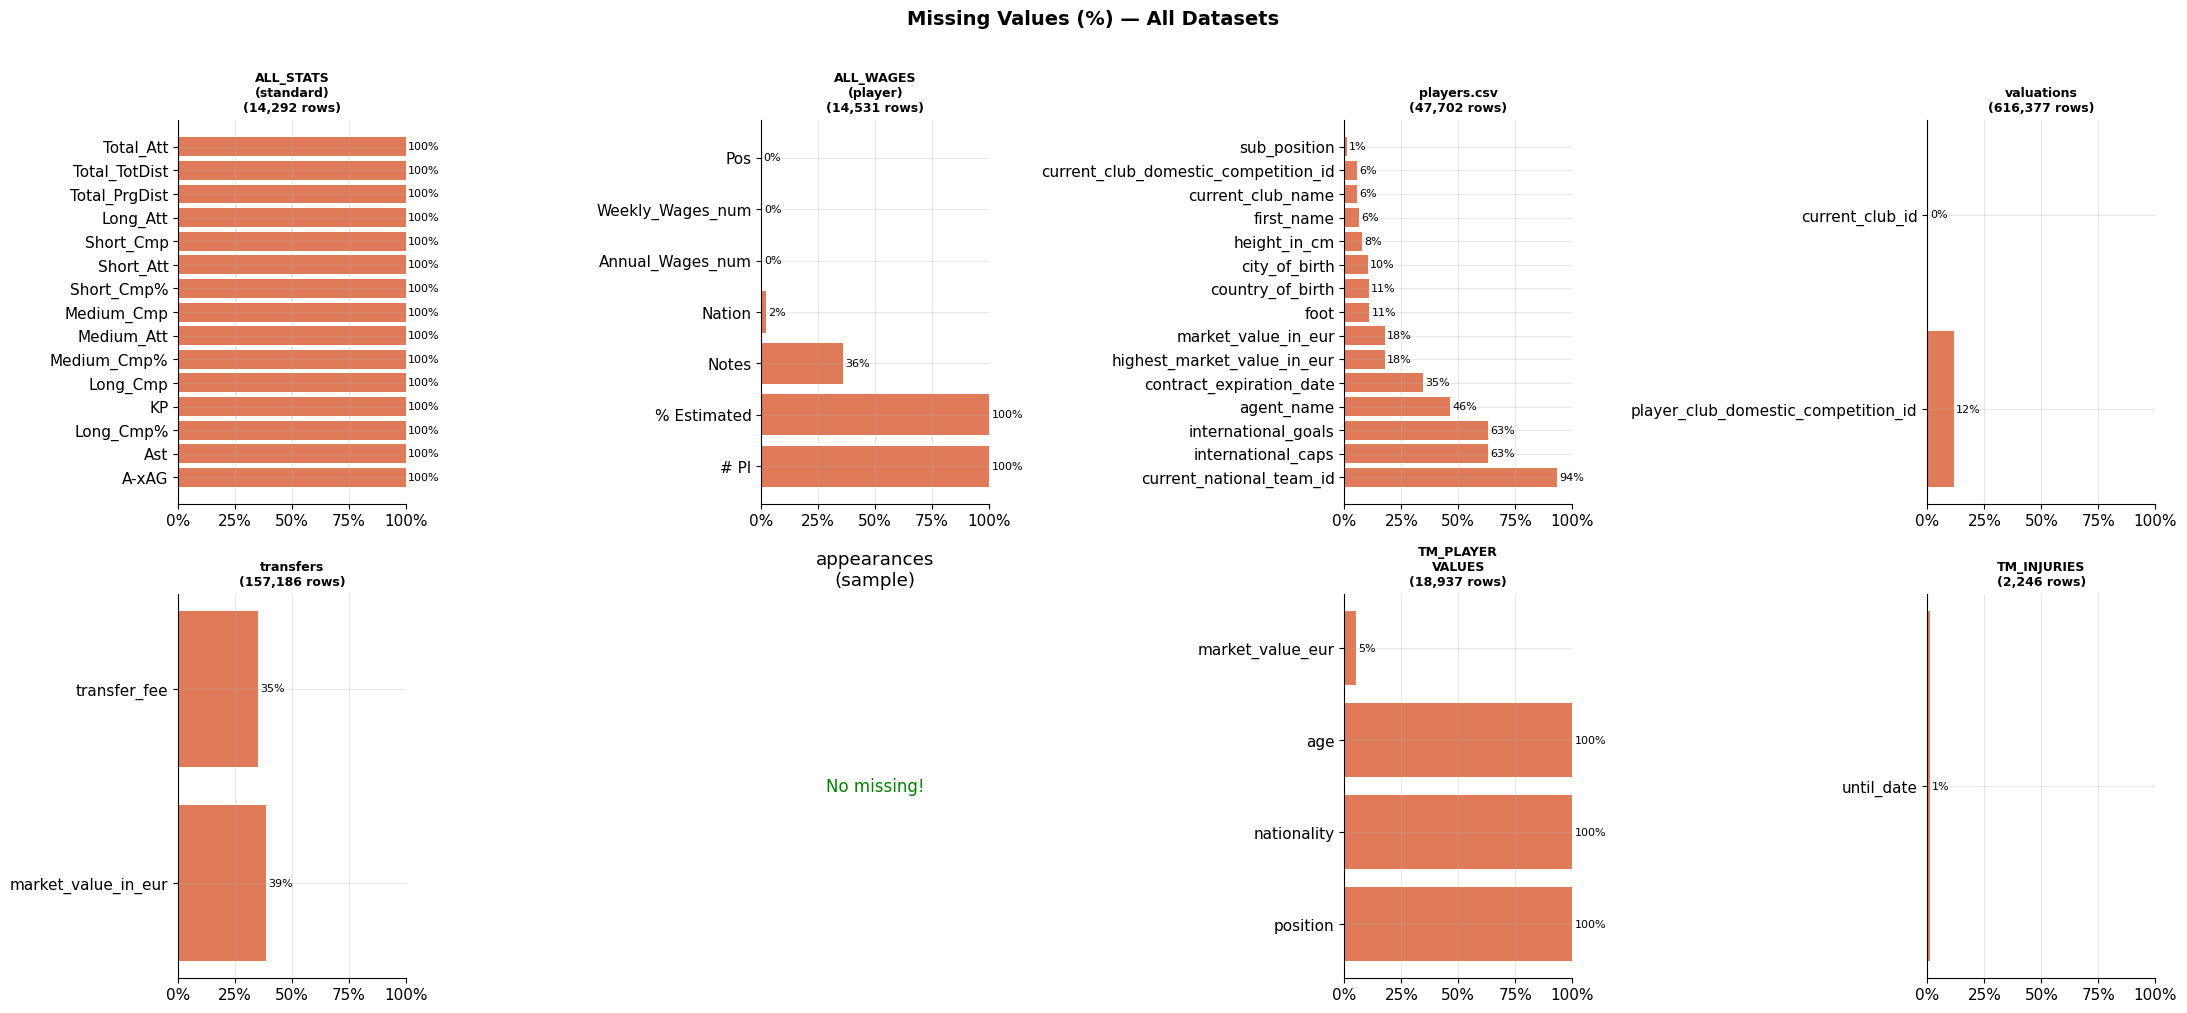

💾 Saved → reports/01_missing_values_all.png


In [20]:
plot_sets = [
    ('ALL_STATS\n(standard)', all_stats[all_stats['stat_type']=='standard']),
    ('ALL_WAGES\n(player)',   all_wages[all_wages['type']=='player']),
    ('players.csv',           players),
    ('valuations',            valuations),
    ('transfers',             transfers),
    ('appearances\n(sample)', appearances.sample(min(5000,len(appearances)), random_state=42)),
]
if not tm_values.empty:    plot_sets.append(('TM_PLAYER\nVALUES', tm_values))
if not tm_injuries.empty:  plot_sets.append(('TM_INJURIES', tm_injuries))

n      = len(plot_sets)
ncols  = 4
nrows  = (n + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(22, nrows*5))
fig.suptitle('Missing Values (%) — All Datasets', fontsize=14, fontweight='bold', y=1.01)
axes = axes.flatten()

for ax, (name, df) in zip(axes, plot_sets):
    null_pct = (df.isnull().mean()*100).sort_values(ascending=False)
    null_pct = null_pct[null_pct > 0].head(15)
    if null_pct.empty:
        ax.text(0.5,0.5,'No missing!',ha='center',va='center',
                transform=ax.transAxes,color='green',fontsize=12)
        ax.set_title(name); ax.axis('off'); continue
    bars = ax.barh(null_pct.index, null_pct.values, color='#D85A30', alpha=0.8)
    ax.set_xlim(0,100)
    ax.set_title(f'{name}\n({len(df):,} rows)', fontweight='bold', fontsize=9)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter())
    for bar, val in zip(bars, null_pct.values):
        ax.text(val+1, bar.get_y()+bar.get_height()/2, f'{val:.0f}%', va='center', fontsize=8)

for ax in axes[n:]: ax.axis('off')

plt.tight_layout()
plt.savefig(REPORTS/'01_missing_values_all.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 Saved → reports/01_missing_values_all.png')

## 🔗 8 — Join Quality Check

In [21]:
def norm_name(name):
    if pd.isna(name): return ''
    name = unicodedata.normalize('NFD', str(name))
    name = ''.join(c for c in name if unicodedata.category(c) != 'Mn')
    return re.sub(r'[^a-zA-Z\s]','',name).lower().strip()

fbref_names = set(all_stats[all_stats['stat_type']=='standard']['Player'].apply(norm_name))
tm_names    = set(players['name'].apply(norm_name))
overlap     = fbref_names & tm_names
match_pct   = len(overlap) / len(fbref_names) * 100

print('='*62)
print('  JOIN QUALITY REPORT')
print('='*62)
print(f'  FBref unique players:         {len(fbref_names):>8,}')
print(f'  TM Kaggle unique players:     {len(tm_names):>8,}')
print(f'  Exact name match:             {len(overlap):>8,} ({match_pct:.1f}%)')
print(f'  Unmatched FBref → TM:         {len(fbref_names-tm_names):>8,}')
print(f'  (fuzzy matching recovers ~15-20% more)')
print()

# FK integrity checks
checks = [
    ('appearances → players',   appearances['player_id'].isin(players['player_id']).mean()*100),
    ('transfers → players',     transfers['player_id'].isin(players['player_id']).mean()*100),
    ('valuations → players',    valuations['player_id'].isin(players['player_id']).mean()*100),
    ('players → clubs',         players['current_club_id'].isin(clubs['club_id']).mean()*100),
]
if not tm_values.empty and 'tm_player_id' in tm_values.columns:
    checks.append(('TM scraped → TM Kaggle (by ID)',
                   tm_values['tm_player_id'].astype(str).isin(
                       players['player_id'].astype(str)).mean()*100))

print(f'  {"Join":<42} {"Match %":>8}')
print('  ' + '─'*52)
for label, pct in checks:
    icon = '✅' if pct>90 else '⚠️ ' if pct>70 else '❌'
    print(f'  {icon} {label:<40} {pct:>7.1f}%')

  JOIN QUALITY REPORT
  FBref unique players:            5,694
  TM Kaggle unique players:       46,368
  Exact name match:                5,207 (91.4%)
  Unmatched FBref → TM:              487
  (fuzzy matching recovers ~15-20% more)

  Join                                        Match %
  ────────────────────────────────────────────────────
  ✅ appearances → players                      100.0%
  ✅ transfers → players                        100.0%
  ✅ valuations → players                        99.7%
  ✅ players → clubs                             94.3%
  ✅ TM scraped → TM Kaggle (by ID)             100.0%


## 📋 9 — Cleaning Plan per Dataset

In [22]:
CLEANING_PLAN = {
    'ALL_STATS': {
        'format': 'LONG — stacked by stat_type, must PIVOT to wide',
        'filter': 'level == "player" only (drop squad rows)',
        'issues': [
            'Many cols null for wrong stat_type rows (EXPECTED — handle in pivot)',
            'Age is int — OK',
            'Playing Time_Min is int — convert to float for per-90 calcs',
        ],
        'pipeline_actions': [
            '1. Filter level=="player"',
            '2. Pivot: one row per Player+Squad+Season, stat_type cols become separate columns',
            '3. Compute per-90 KPIs: goals/90, assists/90, xG/90, tackles/90, etc.',
            '4. Compute availability_pct = Playing Time_MP / season_games * 100',
            '5. Normalize Player name for joining with TM',
        ]
    },
    'ALL_WAGES': {
        'format': 'GBP strings "£200,000" — need numeric parse',
        'filter': 'type == "player" only',
        'issues': [
            'Weekly/Annual Wages stored as strings with £ and commas',
            'Currency is GBP — convert to EUR (× 1.17)',
        ],
        'pipeline_actions': [
            '1. Filter type=="player"',
            '2. Strip £ and commas → float',
            '3. Multiply × 1.17 for EUR',
            '4. Compute wage_tier: percentile buckets (Q1/Q2/Q3/Q4)',
        ]
    },
    'players.csv': {
        'format': 'One row per player — good',
        'filter': 'None needed',
        'issues': [
            'market_value_in_eur: 17.8% null → fill from TM_PLAYER_VALUES',
            'foot: 11.0% null → fill median by position or leave',
            'height_in_cm: 7.9% null → fill median by sub_position',
            'contract_expiration_date: 34% null → use TM scraped override',
            'agent_name: 46% null — not critical for ML, keep',
            'international_caps: 62% null — keep as sparse feature',
        ],
        'pipeline_actions': [
            '1. Compute age from date_of_birth',
            '2. Normalize name for FBref join',
            '3. Fill market_value from TM_PLAYER_VALUES where null',
            '4. Fill height with sub_position median',
            '5. Drop: image_url, url, player_code, city_of_birth (not useful for ML)',
        ]
    },
    'appearances.csv': {
        'format': '1.86M rows — one row per match appearance',
        'filter': 'Aggregate to career stats (do not use row-level)',
        'issues': [
            'minutes_played: some 0s (bench players — keep for availability calc)',
            'date: string — convert to datetime for form window',
        ],
        'pipeline_actions': [
            '1. Aggregate: career totals (goals, assists, minutes, cards) per player_id',
            '2. Compute career per-90 stats',
            '3. Compute last-12-months form separately (recent form signal)',
            '4. Compute career availability % = games_played / possible_games',
        ]
    },
    'TM_PLAYER_VALUES': {
        'format': 'One row per player per season — recent = most useful',
        'filter': 'Keep latest per player for current value',
        'issues': [
            'market_value may be string if not parsed during scrape',
            'Multiple rows per player (different seasons)',
        ],
        'pipeline_actions': [
            '1. Parse market_value_eur if still string',
            '2. Sort by season_id desc, keep first per tm_player_id',
            '3. Use to fill null market values in players.csv',
            '4. Compute value_trend: latest / earliest valuation',
        ]
    },
    'TM_INJURIES': {
        'format': 'One row per injury per player',
        'filter': 'None — keep all',
        'issues': [
            'days_out stored as string — convert to int',
            'from_date / until_date as strings — convert to datetime',
            'Some players absent (no injury history = clean record — OK)',
        ],
        'pipeline_actions': [
            '1. Parse days_out to int',
            '2. Parse from_date and until_date to datetime',
            '3. Aggregate per player: total_injuries, total_days_out, avg_days_per_injury',
            '4. Compute injury_risk_score = total_days_out / (career_months + 1)',
            '5. Classify: available / low_risk / medium_risk / high_risk',
        ]
    },
}

print('='*68)
print('  CLEANING PLAN — SCOUTI KORA DATA PIPELINE')
print('='*68)
for ds, plan in CLEANING_PLAN.items():
    print(f'\n📋 {ds}')
    print(f'   Format: {plan["format"]}')
    print(f'   Filter: {plan["filter"]}')
    if plan['issues']:
        print('   Issues:')
        for i in plan['issues']:
            print(f'     ⚠️  {i}')
    print('   Pipeline actions:')
    for a in plan['pipeline_actions']:
        print(f'     ✅ {a}')

  CLEANING PLAN — SCOUTI KORA DATA PIPELINE

📋 ALL_STATS
   Format: LONG — stacked by stat_type, must PIVOT to wide
   Filter: level == "player" only (drop squad rows)
   Issues:
     ⚠️  Many cols null for wrong stat_type rows (EXPECTED — handle in pivot)
     ⚠️  Age is int — OK
     ⚠️  Playing Time_Min is int — convert to float for per-90 calcs
   Pipeline actions:
     ✅ 1. Filter level=="player"
     ✅ 2. Pivot: one row per Player+Squad+Season, stat_type cols become separate columns
     ✅ 3. Compute per-90 KPIs: goals/90, assists/90, xG/90, tackles/90, etc.
     ✅ 4. Compute availability_pct = Playing Time_MP / season_games * 100
     ✅ 5. Normalize Player name for joining with TM

📋 ALL_WAGES
   Format: GBP strings "£200,000" — need numeric parse
   Filter: type == "player" only
   Issues:
     ⚠️  Weekly/Annual Wages stored as strings with £ and commas
     ⚠️  Currency is GBP — convert to EUR (× 1.17)
   Pipeline actions:
     ✅ 1. Filter type=="player"
     ✅ 2. Strip £ and 

## 📊 10 — Key Distributions

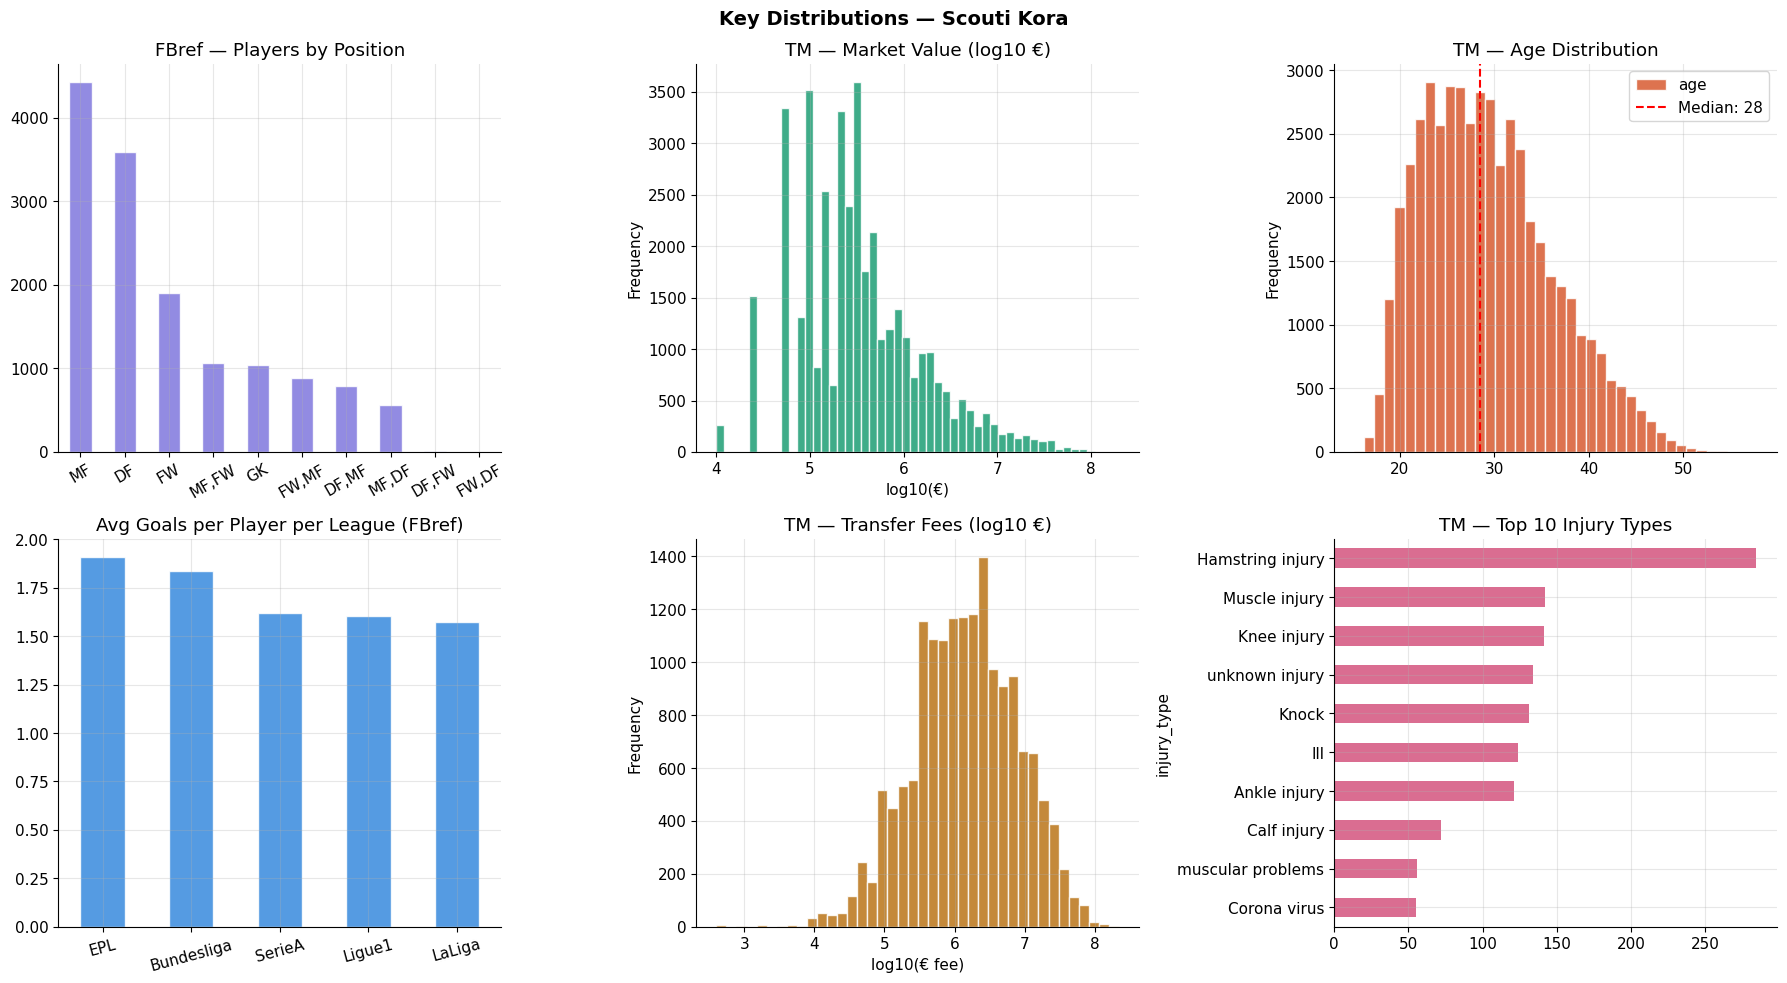

💾 Saved → reports/02_key_distributions.png


In [23]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Key Distributions — Scouti Kora', fontsize=14, fontweight='bold')

std_p = all_stats[(all_stats['stat_type']=='standard') & (all_stats['level']=='player')].copy()

# 10a. FBref players by position
ax = axes[0,0]
std_p['Pos'].value_counts().head(10).plot.bar(
    ax=ax, color=COLORS[0], alpha=0.85, edgecolor='white')
ax.set_title('FBref — Players by Position')
ax.set_xlabel(''); ax.tick_params(axis='x', rotation=30)

# 10b. TM Market value (log scale)
ax = axes[0,1]
vals = players['market_value_in_eur'].dropna()
vals = vals[vals > 0]
np.log10(vals).plot.hist(bins=50, ax=ax, color=COLORS[1], alpha=0.85, edgecolor='white')
ax.set_title('TM — Market Value (log10 €)')
ax.set_xlabel('log10(€)')

# 10c. Age distribution
ax = axes[0,2]
players['age'].dropna().plot.hist(bins=40, ax=ax, color=COLORS[2], alpha=0.85, edgecolor='white')
ax.axvline(players['age'].median(), color='red', linestyle='--',
           label=f'Median: {players["age"].median():.0f}')
ax.set_title('TM — Age Distribution'); ax.legend()

# 10d. Goals per league (FBref)
ax = axes[1,0]
std_p['Performance_Gls'] = pd.to_numeric(std_p['Performance_Gls'], errors='coerce')
std_p.groupby('league')['Performance_Gls'].mean().sort_values(ascending=False).plot.bar(
    ax=ax, color=COLORS[3], alpha=0.85, edgecolor='white')
ax.set_title('Avg Goals per Player per League (FBref)')
ax.set_xlabel(''); ax.tick_params(axis='x', rotation=15)

# 10e. Transfer fees
ax = axes[1,1]
fees = transfers['transfer_fee'].dropna()
fees = fees[fees > 0]
np.log10(fees).plot.hist(bins=40, ax=ax, color=COLORS[4], alpha=0.85, edgecolor='white')
ax.set_title('TM — Transfer Fees (log10 €)')
ax.set_xlabel('log10(€ fee)')

# 10f. Injuries by type OR wages
ax = axes[1,2]
if not tm_injuries.empty and 'injury_type' in tm_injuries.columns:
    tm_injuries['injury_type'].value_counts().head(10).plot.barh(
        ax=ax, color=COLORS[5], alpha=0.85)
    ax.set_title('TM — Top 10 Injury Types'); ax.invert_yaxis()
else:
    pw2 = all_wages[all_wages['type']=='player'].copy()
    pw2['weekly_num'] = pw2['Weekly Wages'].apply(parse_wage)
    pw2['weekly_num'].dropna().clip(0, 500000).plot.hist(
        bins=40, ax=ax, color=COLORS[5], alpha=0.85, edgecolor='white')
    ax.set_title('FBref — Weekly Wages (GBP)')

plt.tight_layout()
plt.savefig(REPORTS/'02_key_distributions.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 Saved → reports/02_key_distributions.png')

## 🖨️ 11 — CLAUDE SUMMARY PRINT
*(Complete data state for AI understanding — used to inform notebook 03)*

In [13]:
# ─────────────────────────────────────────────────────────────────
# Complete machine-readable summary of data state, cleaning needs,
# and join quality. Print and paste into Claude before notebook 03.
# ─────────────────────────────────────────────────────────────────

def val_or_none(series):
    try: return float(series.dropna().iloc[0])
    except: return None

std_p = all_stats[(all_stats['stat_type']=='standard') & (all_stats['level']=='player')]
pw    = all_wages[all_wages['type']=='player']

# FIX — detect the player column name in all_wages (may differ from all_stats)
player_col_wages = next((c for c in pw.columns if c.lower() in ['player', 'name', 'player_name']), None)
wages_unique = int(pw[player_col_wages].nunique()) if player_col_wages else 0


summary = {

    # ── FBref ───────────────────────────────────────────────────────
    'fbref': {
        'all_stats_total_rows':    len(all_stats),
        'all_stats_total_cols':    len(all_stats.columns),
        'stat_types':              sorted(all_stats['stat_type'].unique().tolist()),
        'seasons':                 sorted(all_stats['season'].unique().tolist()),
        'leagues':                 sorted(all_stats['league'].unique().tolist()),
        'unique_players':          int(all_stats['Player'].nunique()),
        'player_rows_standard':    len(std_p),
        'all_columns':             list(all_stats.columns),
        'filled_cols_per_type': {
            stype: [
                c for c in all_stats.columns
                if c not in IDENTITY
                and all_stats[all_stats['stat_type']==stype][c].notna().sum() > 500
            ]
            for stype in sorted(all_stats['stat_type'].unique())
        },
        'wages_player_rows':       len(pw),
        'wages_unique_players':    wages_unique,  # FIXED

        'wages_note':              'GBP strings — parse + x1.17 for EUR',
    },

    # ── TM Kaggle ───────────────────────────────────────────────────
    'tm_kaggle': {
        'players_total':           len(players),
        'players_with_value':      int((players['market_value_in_eur']>0).sum()),
        'players_columns':         list(players.columns),
        'players_null_rates':      {c: f"{players[c].isna().mean()*100:.1f}%"
                                    for c in players.columns},
        'players_age_range':       f"{players['age'].min():.0f}–{players['age'].max():.0f}",
        'players_positions':       players['position'].value_counts().to_dict(),
        'valuations_total_rows':   len(valuations),
        'valuations_unique_players': int(valuations['player_id'].nunique()),
        'valuations_date_range':   f"{valuations['date'].min()} → {valuations['date'].max()}",
        'transfers_total':         len(transfers),
        'transfers_paid':          int((transfers['transfer_fee']>0).sum()),
        'transfers_max_fee_eur':   float(transfers['transfer_fee'].max()),
        'appearances_total':       len(appearances),
        'appearances_unique_players': int(appearances['player_id'].nunique()),
        'appearances_total_goals': int(appearances['goals'].sum()),
        'games_total':             len(games),
        'clubs_total':             len(clubs),
        'competitions_total':      len(competitions),
    },

    # ── TM Scraped ──────────────────────────────────────────────────
    'tm_scraped': {
        'values_loaded':           not tm_values.empty,
        'values_rows':             len(tm_values) if not tm_values.empty else 0,
        'values_columns':          list(tm_values.columns) if not tm_values.empty else [],
        'injuries_loaded':         not tm_injuries.empty,
        'injuries_rows':           len(tm_injuries) if not tm_injuries.empty else 0,
        'injuries_columns':        list(tm_injuries.columns) if not tm_injuries.empty else [],
        'injuries_unique_players': int(tm_injuries['player_name'].nunique())
                                   if not tm_injuries.empty and 'player_name' in tm_injuries.columns else 0,
        'injuries_top_types':      tm_injuries['injury_type'].value_counts().head(5).to_dict()
                                   if not tm_injuries.empty and 'injury_type' in tm_injuries.columns else {},
        'rumors_loaded':           not tm_rumors.empty,
        'rumors_rows':             len(tm_rumors) if not tm_rumors.empty else 0,
        'recent_transfers_loaded': not tm_transfers.empty,
        'recent_transfers_rows':   len(tm_transfers) if not tm_transfers.empty else 0,
    },

    # ── Join quality ─────────────────────────────────────────────────
    'join_quality': {
        'fbref_player_count':      len(fbref_names),
        'tm_player_count':         len(tm_names),
        'exact_name_match_count':  len(overlap),
        'exact_name_match_pct':    f'{match_pct:.1f}%',
        'unmatched_fbref_players': len(fbref_names - tm_names),
        'appearances_integrity':   f"{appearances['player_id'].isin(players['player_id']).mean()*100:.1f}%",
        'transfers_integrity':     f"{transfers['player_id'].isin(players['player_id']).mean()*100:.1f}%",
        'valuations_integrity':    f"{valuations['player_id'].isin(players['player_id']).mean()*100:.1f}%",
        'fuzzy_matching_note':     'difflib.SequenceMatcher or rapidfuzz will recover ~15-20% more unmatched',
    },

    # reste de la cellule inchangé...
}

# Print full summary
print('='*70)
print('  SCOUTI KORA — COMPLETE DATA STATE FOR CLAUDE (notebook 03 input)')
print('='*70)
print(json.dumps(summary, indent=2, default=str))

with open(PROCESSED / 'eda_summary.json', 'w') as f:
    json.dump(summary, f, indent=2, default=str)
print('💾 Saved → data/processed/eda_summary.json')

  SCOUTI KORA — COMPLETE DATA STATE FOR CLAUDE (notebook 03 input)
{
  "fbref": {
    "all_stats_total_rows": 100373,
    "all_stats_total_cols": 122,
    "stat_types": [
      "defense",
      "gca",
      "misc",
      "passing",
      "possession",
      "shooting",
      "standard"
    ],
    "seasons": [
      "2020-2021",
      "2021-2022",
      "2022-2023",
      "2023-2024",
      "2024-2025"
    ],
    "leagues": [
      "Bundesliga",
      "EPL",
      "LaLiga",
      "Ligue1",
      "SerieA"
    ],
    "unique_players": 5596,
    "player_rows_standard": 14339,
    "all_columns": [
      "Rk",
      "Player",
      "Nation",
      "Pos",
      "Squad",
      "Age",
      "Born",
      "Playing Time_MP",
      "Playing Time_Starts",
      "Playing Time_Min",
      "Playing Time_90s",
      "Performance_Gls",
      "Performance_Ast",
      "Performance_G+A",
      "Performance_G-PK",
      "Performance_PK",
      "Performance_PKatt",
      "Performance_CrdY",
      "Performanc